# Chương 1. Phân tích khám phá chuỗi thời gian

**Mục tiêu.** Mô tả bộ dữ liệu S&P 500, chọn chuỗi nghiên cứu, nhận diện trực quan xu hướng, mùa vụ, nhiễu, phân tích cấu trúc tự tương quan (ACF/PACF) và đánh giá sơ bộ tính dừng qua rolling statistics.

**Dữ liệu.** [S&P 500 Stocks: 25 Years of Data](https://www.kaggle.com/datasets/darkmatternet/s-and-p-500-stocks-25-years-of-data-updated-daily) – OHLCV theo ngày của các mã thuộc S&P 500. Giai đoạn phân tích được cố định trong `dmprep/config.py` để kết quả tái lập được dù dataset cập nhật hằng ngày.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dmprep import config
from dmprep.data import load_sp500, load_main_series

config.set_seed()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

RESULTS: dict = {}  # mọi score / p-value của chương này được lưu vào đây

## 1.1 Tải và mô tả dữ liệu

In [2]:
prices = load_sp500()
print("Kích thước:", prices.shape)
print("Số mã cổ phiếu:", prices["ticker"].nunique())
print("Khoảng thời gian:", prices["date"].min().date(), "→", prices["date"].max().date())
print("Các cột:", list(prices.columns))
RESULTS["n_rows"] = len(prices)
RESULTS["n_tickers"] = prices["ticker"].nunique()
prices.head()

Kích thước: (2391731, 7)
Số mã cổ phiếu: 500
Khoảng thời gian: 2005-01-03 → 2025-12-31
Các cột: ['date', 'open', 'high', 'low', 'close', 'volume', 'ticker']


,date,open,high,low,close,volume,ticker
0,2005-01-03,14.323501,14.371048,13.966900,14.192747,3378826.0,A
1,2005-01-04,14.133309,14.258120,13.699445,13.818312,3746920.0,A
2,2005-01-05,13.770767,14.056048,13.741049,13.812370,3898603.0,A
3,2005-01-06,13.907467,13.931240,13.485489,13.509262,3158641.0,A
4,2005-01-07,13.479540,13.640012,13.449824,13.497371,2624326.0,A


**Phân tích kết quả.**

> TODO: mô tả các cột, kiểu dữ liệu, khoảng thời gian; lưu ý survivorship bias (chỉ chứa các mã *hiện tại* của S&P 500).

## 1.2 Chọn chuỗi nghiên cứu và lịch giao dịch

Thị trường chỉ giao dịch vào ngày làm việc và nghỉ các ngày lễ của sàn NYSE. Vì vậy "khoảng trống" cuối tuần và ngày lễ **không phải** giá trị thiếu. Ta đối chiếu chỉ mục ngày của chuỗi với lịch giao dịch chính thức để tìm các ngày thiếu thực sự.

In [3]:
import holidays

series = load_main_series()
n = len(series)
print(f"{series.name}: n = {n} phiên, {series.index.min().date()} → {series.index.max().date()}")

years = range(series.index.min().year, series.index.max().year + 1)
nyse_holidays = pd.to_datetime(list(holidays.financial_holidays("NYSE", years=years).keys()))
bdays = pd.bdate_range(series.index.min(), series.index.max())
trading_days = bdays[~bdays.isin(nyse_holidays)]
missing_days = trading_days.difference(series.index)

print("Số ngày giao dịch theo lịch NYSE:", len(trading_days))
print("Số ngày giao dịch bị thiếu trong dữ liệu:", len(missing_days))
print("Số giá trị NaN:", int(series.isna().sum()))

RESULTS["main_ticker"] = series.name
RESULTS["n_obs"] = n
RESULTS["n_missing_trading_days"] = len(missing_days)

AAPL: n = 5283 phiên, 2005-01-03 → 2025-12-31


Số ngày giao dịch theo lịch NYSE: 5283
Số ngày giao dịch bị thiếu trong dữ liệu: 0
Số giá trị NaN: 0


**Phân tích kết quả.**

> TODO: giải thích vì sao chọn mã này, các ngày thiếu (nếu có) rơi vào đâu (đóng cửa bất thường như 11/9/2001, bão Sandy 2012...).

## 1.3 Time plot: xu hướng, mùa vụ và nhiễu

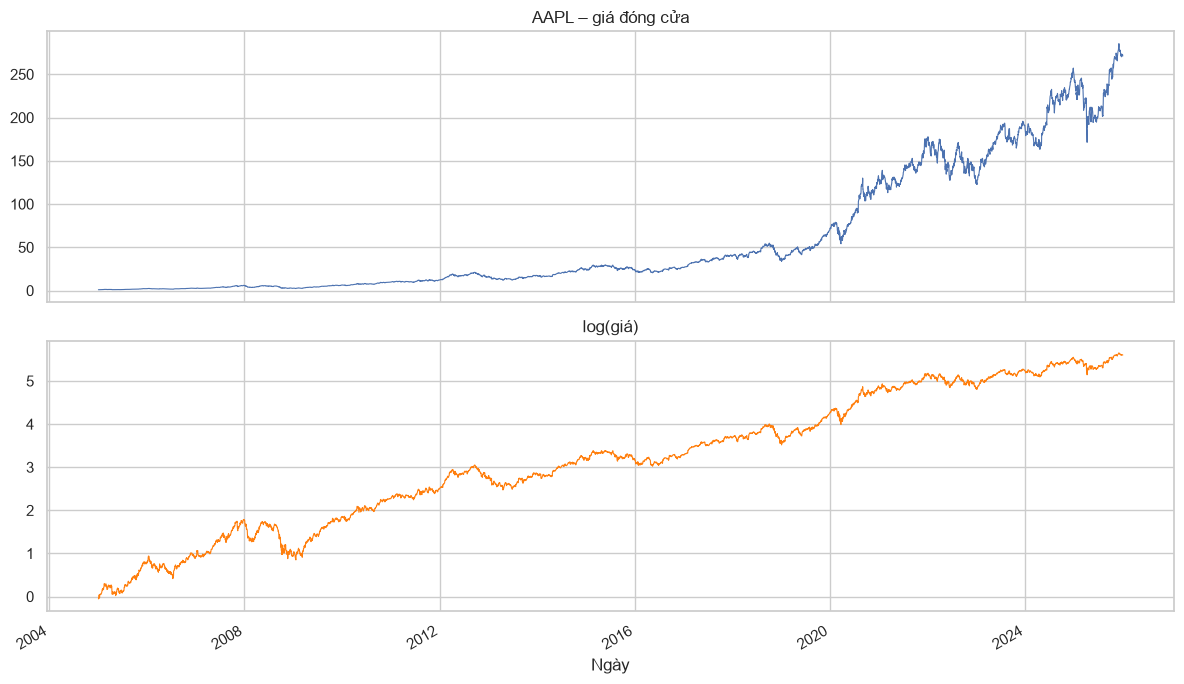

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
series.plot(ax=axes[0], lw=0.8, title=f"{series.name} – giá đóng cửa")
np.log(series).plot(ax=axes[1], lw=0.8, color="tab:orange", title="log(giá)")
axes[1].set_xlabel("Ngày")
plt.tight_layout()
plt.show()

**Phân tích kết quả.**

> TODO: nhận xét bằng mắt về trend (tăng trưởng dài hạn), seasonality (có/không, chu kỳ tuần/năm?), noise và các giai đoạn biến động mạnh (2008, 2020, 2022).

## 1.4 ACF và PACF

Hàm tự tương quan tại độ trễ $k$:

$$\rho_k = \frac{\sum_{t=k+1}^{n}(y_t-\bar y)(y_{t-k}-\bar y)}{\sum_{t=1}^{n}(y_t-\bar y)^2}$$

PACF đo tương quan giữa $y_t$ và $y_{t-k}$ sau khi loại bỏ ảnh hưởng của các độ trễ trung gian $1,\dots,k-1$. Độ trễ tối đa chọn theo $\min(10\log_{10} n,\ n/5)$.

> TODO: viết lại phần lý thuyết bằng lời của bạn.

In [5]:
max_lag = int(min(10 * np.log10(n), n / 5))
RESULTS["acf_max_lag"] = max_lag
print("max_lag =", max_lag)

# TODO: vẽ ACF, PACF cho (1) chuỗi giá gốc và (2) log-return để so sánh.
# from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# log_ret = np.log(series).diff().dropna()
# fig, axes = plt.subplots(2, 2, figsize=(14, 7))
# plot_acf(series, lags=max_lag, ax=axes[0, 0]); plot_pacf(series, lags=max_lag, ax=axes[0, 1])
# plot_acf(log_ret, lags=max_lag, ax=axes[1, 0]); plot_pacf(log_ret, lags=max_lag, ax=axes[1, 1])

max_lag = 37


**Phân tích kết quả.**

> TODO: ACF của giá giảm rất chậm (dấu hiệu không dừng); ACF/PACF của log-return gần như nằm trong dải tin cậy. Các lag có ý nghĩa của PACF sẽ dùng để chọn p ở chương 3.

## 1.5 Rolling statistics

Trung bình trượt và độ lệch chuẩn trượt với cửa sổ $w$:

$$\mu_t^{(w)} = \frac{1}{w}\sum_{i=0}^{w-1} y_{t-i}, \qquad \sigma_t^{(w)} = \sqrt{\frac{1}{w-1}\sum_{i=0}^{w-1}\big(y_{t-i}-\mu_t^{(w)}\big)^2}$$

Đề yêu cầu cửa sổ 7, 30, 90 ngày *hoặc tương đương*. Với dữ liệu phiên giao dịch, có thể dùng cửa sổ theo lịch (`"7D"`, `"30D"`, `"90D"`) hoặc theo số phiên (5, 21, 63). Hãy chọn và giải thích.

In [6]:
WINDOWS = {"7D": 5, "30D": 21, "90D": 63}  # cửa sổ lịch -> số phiên tương đương

# TODO: tính và vẽ rolling mean / std cho từng cửa sổ (trên giá và trên log-return).
# fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
# for label, w in WINDOWS.items():
#     series.rolling(w).mean().plot(ax=axes[0], label=f"mean {label}")
#     series.rolling(w).std().plot(ax=axes[1], label=f"std {label}")

**Phân tích kết quả.**

> TODO: mean và std thay đổi theo thời gian → chuỗi giá không dừng (kết luận sơ bộ, sẽ kiểm định ở chương 2).

## Lưu kết quả

Toàn bộ con số của chương được ghi ra `data/processed/results/` để chương báo cáo tham chiếu.

In [7]:
config.save_results("01_ts_eda", RESULTS)
RESULTS

{'n_rows': 2391731,
 'n_tickers': 500,
 'main_ticker': 'AAPL',
 'n_obs': 5283,
 'n_missing_trading_days': 0,
 'acf_max_lag': 37}